## readme

The purpose of this notebook is to explore the concepts of explainability with the models we are building. 

The first pass will look at the unsupervised models that have been built on the QAQC systems

The goal, is to be able to explain why any given sample or event has been flagged as an anomaly

In [121]:
## Packages

import h2o
import numpy as np
import pandas as pd
import pyodbc
from h2o.estimators import H2OExtendedIsolationForestEstimator, H2ORandomForestEstimator
import warnings
import json

h2o.init(nthreads=-1,enable_assertions=False)
warnings.filterwarnings('ignore')

Checking whether there is an H2O instance running at http://localhost:54321. connected.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,2 hours 51 mins
H2O_cluster_timezone:,America/New_York
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.44.0.2
H2O_cluster_version_age:,3 months and 20 days
H2O_cluster_name:,H2O_from_python_dan_larson_1rkqv9
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,6.822 Gb
H2O_cluster_total_cores:,8
H2O_cluster_allowed_cores:,8
H2O_cluster_status:,"locked, healthy"


In [ ]:
## Load Model
EIF_model = h2o.load_model('C:/Users/dan.larson/Documents/MLAR/models/Unsupervised/unsupervisedModel_X3')

In [122]:
import config

In [123]:
config.customerName

'jaguar'

In [124]:
# Move to DB connection stub
import pyodbc # import oracledb

# Check lims dsn connection to database before proceeding
def get_lims_connection():
    global odbcLimsConnection
    # odbcLimsConnection = oracledb.connect(user=config.limsdb_username, password=config.limsdb_password,
    # dsn=config.limsdb_dsn)
    odbcLimsConnection = pyodbc.connect('DRIVER=' + config.limsdb_driver + ';DATABASE=' + config.limsdb_database +
                                        ';UID=' + config.limsdb_username + ';PWD=' + config.limsdb_password +
                                        ';SERVER=' + config.limsdb_hostname + ';PORT=' + config.limsdb_port +
                                        ';Trusted_Connection=yes')
    return odbcLimsConnection


if __name__ == '__main__':
    try:  # GET THE CONNECTION OBJECT (ENGINE) FOR THE DATABASE
        get_lims_connection()
    except Exception as error:
        exit("Connection could not be made due to the following error: \n", error)


# Check mlar dsn connection to database before proceeding
def get_mlar_connection():
    global odbcMlarConnection
    # odbcMlarConnection = oracledb.connect(user=config.mlardb_username, password=config.mlardb_password,
    # dsn=config.mlardb_dsn)
    odbcMlarConnection = pyodbc.connect('DRIVER=' + config.mlardb_driver + ';DATABASE=' + config.mlardb_database +
                                        ';UID=' + config.mlardb_username + ';PWD=' + config.mlardb_password +
                                        ';SERVER=' + config.mlardb_hostname + ';PORT=' + config.mlardb_port +
                                        ';Trusted_Connection=yes')
    return odbcMlarConnection


if __name__ == '__main__':
    try:
        # GET THE CONNECTION OBJECT (ENGINE) FOR THE DATABASE
        get_mlar_connection()
    except Exception as error:
        exit("Connection could not be made due to the following error: \n", error)

In [ ]:
# Start and Finish Logs - MOVE TO CONFIG
sql_command = "select MIN(AUDIT_TIMESTAMP),MAX(AUDIT_TIMESTAMP) from SAMPLE_AUDIT_DECRYPT"
with odbcLimsConnection.cursor() as lims_cursor_fetch_one:
    lims_cursor_fetch_one.execute(sql_command)
    response = lims_cursor_fetch_one.fetchone()
startLog = response[0]
endLog = response[1]

In [125]:
sql = '''
select sad.* from sample_audit_decrypt sad 
left join t_mlar_log tml on sad.counter = tml.audit_counter and sad.table_name =tml.audit_table_name  and sad.table_key =tml.audit_table_key  and sad.audit_type  = tml.audit_type 
and sad."action" = tml.audit_action and sad.audit_timestamp = tml.audit_timestamp 
'''

In [128]:

df = pd.read_sql(sql,odbcLimsConnection)

In [126]:
def loads_json(x):
    try:
        return json.loads(x) if pd.notna(x) else pd.Series()
    except json.JSONDecodeError as e:
        print(f"Error decoding JSON: {e}")
        print(f"Problematic JSON string: {x}")
        return pd.Series()


In [129]:


df['trans_string'] = df['trans_string'].apply(loads_json)
jsonData = pd.json_normalize(df['trans_string'])
jsonData = jsonData.replace(np.nan, "█").replace("▄", ",", regex=True)
df = pd.concat([df,jsonData],axis=1)



Error decoding JSON: Expecting ',' delimiter: line 1 column 146 (char 145)
Problematic JSON string: {"TEST_NUMBER":"49836","RESULT_NUMBER":"251053","ANALYSIS":"TOTAL_AAV","NAME":"Test Method","REPLICATE_COUNT":"0","STATUS":"E","ENTRY":"ATM-5\","FORMATTED_ENTRY":"ATM-5\","ENTERED_ON":"2022-04-04 15:09:16","ENTERED_BY":"MMESSNER","CHANGED_ON":"2022-04-04 15:09:16","ENTRY_TYPE":"T"}
Error decoding JSON: Invalid control character at: line 1 column 316 (char 315)
Problematic JSON string: {"SAMPLE_NUMBER":"24420","TEST_NUMBER":"52623","RESULT_NUMBER":"260553","ORDER_NUMBER":"4","ANALYSIS":"ALIQUOT","NAME":"Identity","REPORTED_NAME":"Identity","REPLICATE_COUNT":"0","RESULT_TYPE":"T","STATUS":"E","OLD_STATUS":"N","MODIFIED_RESULT":"F","ALLOW_OUT":"T","ENTRY":"Cell line is consistent with Human origin
Sample exhibits a sequence match of >= 98% with 4X coverage when compared to the expected sequence for Human","FORMATTED_ENTRY":"Cell line is consistent with Human origin
Sample exhibits a sequenc

In [130]:
# Drop unnecessary or duplicated columns, replace NaN values and comma-replacement character
# jsonDataFrame = jsonDataFrame.drop(columns=['SAMPLE_NUMBER']).replace(np.nan,-999).replace("▄",",",regex=True)

unsupervisedFeatures = list(df.drop(columns=['t_mlar', 't_mlar_severity']).columns.values) 

In [23]:
df['FORMULATION']

0       -999
1       -999
2       -999
3       -999
4       -999
        ... 
6298    -999
6299    -999
6300    -999
6301    -999
6302    -999
Name: FORMULATION, Length: 6303, dtype: object

In [32]:
df['t_mlar_severity'].value_counts()

t_mlar_severity
0    565142
2      3917
3      1824
1       424
Name: count, dtype: int64

In [131]:
hdf=h2o.H2OFrame(df)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [132]:
global_surrogate_data = hdf[:, :]
global_surrogate_data["anomaly"] = (global_surrogate_data["t_mlar_severity"] > 0).ifelse(1, 0)
global_surrogate_data["anomaly"].table()

anomaly,Count
0,565142
1,6165


In [133]:
from h2o.estimators import H2ORandomForestEstimator

global_surrogate_dt = H2ORandomForestEstimator(model_id = "global_surrogate_decision_tree.hex", 
                                               ntrees = 1, max_depth = 20,
                                               sample_rate = 1, mtries = -1)
global_surrogate_dt.train(training_frame = global_surrogate_data, x = unsupervisedFeatures, y = "anomaly")

drf Model Build progress: |██████████████████████████████████████████████████████| (done) 100%


Model Details
=============
H2ORandomForestEstimator : Distributed Random Forest
Model Key: global_surrogate_decision_tree.hex


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    1                  1                           7828                   20           20           20            342           342           342

ModelMetricsRegression: drf
** Reported on train data. **

MSE: NaN
RMSE: NaN
MAE: NaN
RMSLE: NaN
Mean Residual Deviance: NaN

Scoring History: 
    timestamp            duration    number_of_trees    training_rmse    training_mae    training_deviance
--  -------------------  ----------  -----------------  ---------------  --------------  -------------------
    2024-02-28 14:35:33  0.013 sec   0                  nan              nan             nan

Variable Importances: 
variable            relative_importance    scaled_importance     percentage
------------------  ---------------------  --------------------  --------------------
trans_order         4387.06103515625       1.0                   0.7200321393623542
RESULT_NUMBER       410.8084716796875      0.0936409291750499    0.06742447856578987
counter             218.51913452148438     0.049809914375559074  0.03586473920928949
audit_type          152.2232666015625      0.03469823314098043   0.02498384304059388
ANALYSIS            142.9428253173828      0.032582821203510276  0.023460678457624583
table_name          141.7763214111328      0.03231692476466384   0.023269224475913154
reason              134.4273681640625      0.030641782069319837  0.02206306789724739
OPTIONAL            89.49567413330078      0.020399915436807525  0.014688594754775637
user_name           71.44013214111328      0.016284280425692518  0.011725205272887894
TEST_NUMBER         54.47595977783203      0.012417415518335001  0.008940938261018048
---                 ---                    ---                   ---
T_ACQUIRED_BY       0.0                    0.0                   0.0
T_ACQUIRED_ON       0.0                    0.0                   0.0
T_INST_DATA_FILE    0.0                    0.0                   0.0
T_INST_DATA_FILE_2  0.0                    0.0                   0.0
DUE_DATE            0.0                    0.0                   0.0
STAB_PULL_DATE      0.0                    0.0                   0.0
STAB_PULL_BY        0.0                    0.0                   0.0
AUDIT_REVIEWED_BY   0.0                    0.0                   0.0
AUDIT_REVIEWED_ON   0.0                    0.0                   0.0
T_RECEIPT_COMMENT   0.0                    0.0                   0.0
[318 rows x 4 columns]


[tips]
Use `model.explain()` to inspect the model.
--
Use `h2o.display.toggle_user_tips()` to switch on/off this section.

In [135]:
h2o.save_model(global_surrogate_dt)

'C:\\Users\\dan.larson\\Documents\\MLAR\\notebooks\\explainability\\global_surrogate_decision_tree.hex'

In [41]:
instance = global_surrogate_data[global_surrogate_data["anomaly"]==1]

In [42]:
instance_data = instance[1,:]

contributions progress: |

████████████████████████████████████████████████████████| (done) 100%


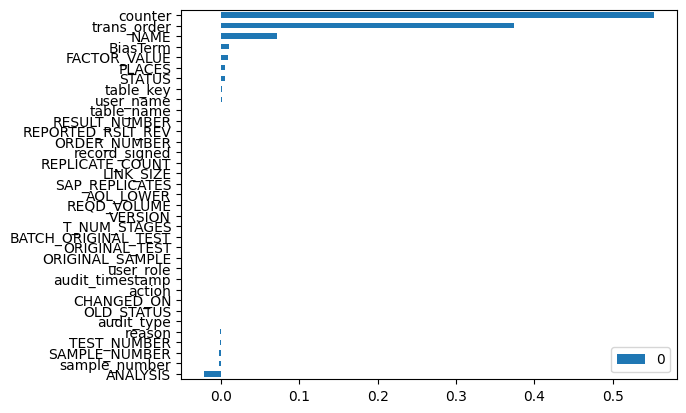

In [44]:

forced_data = global_surrogate_dt.predict_contributions(instance_data)
forced_data = forced_data.as_data_frame()
forced_data = forced_data.transpose()
forced_data = forced_data[forced_data[0]!=0.0]
forced_data = forced_data.sort_values(by=0,ascending=True)
ax = forced_data.plot.barh(stacked=True)

In [66]:
sql = '''
select sad.* from sample_audit_decrypt sad 
inner join t_mlar_log tml on sad.counter = tml.audit_counter and sad.table_name =tml.audit_table_name  and sad.table_key =tml.audit_table_key  and sad.audit_type  = tml.audit_type 
and sad."action" = tml.audit_action and sad.audit_timestamp = tml.audit_timestamp 
limit 1
'''

In [67]:
df = pd.read_sql(sql,odbcLimsConnection)

In [68]:
df

,counter,sample_number,table_name,table_key,audit_type,action,reason,trans_string,trans_order,user_name,audit_timestamp,record_signed,user_role,t_mlar,t_mlar_severity
0,1,6088,TEST,15950,CancelSample,Update,Samples were not part of batch record,"{""TEST_NUMBER"":""15950"",""ANALYSIS"":""INFO"",""REPL...",1,WJONES,2020-10-27 14:40:08,T,_SUPERVISOR,T,0


In [158]:

## Packages

import h2o
import numpy as np
import pandas as pd
import pyodbc
import warnings
import json

h2o.init(nthreads=-1,enable_assertions=False)
warnings.filterwarnings('ignore')

sql = '''

select sad.* from sample_audit_decrypt sad 
inner join t_mlar_log tml on sad.counter = tml.audit_counter and sad.table_name =tml.audit_table_name  and sad.table_key =tml.audit_table_key  and sad.audit_type  = tml.audit_type 
and sad."action" = tml.audit_action and sad.audit_timestamp = tml.audit_timestamp 
where sample_number = 10262 and sad.audit_type = 'FileImport'

'''

instance_data = pd.read_sql(sql,odbcLimsConnection)


def get_explain_values(df): 
    #df['trans_string'] = df['trans_string'].apply(loads_json)
    jsonData = pd.json_normalize(df['trans_string'])
    jsonData = jsonData.replace(np.nan, "█").replace("▄", ",", regex=True)
    df = pd.concat([df,jsonData],axis=1)
    df = h2o.H2OFrame(df)

    global_surrogate_dt = h2o.load_model('global_surrogate_decision_tree.hex')

    forced_data = global_surrogate_dt.predict_contributions(df)
    forced_data = forced_data.as_data_frame()
    forced_data = forced_data.transpose()
    forced_data = forced_data[forced_data[0]!=0.0]
    forced_data = forced_data.sort_values(by=0,ascending=True)
    return forced_data


forced_data = get_explain_values(instance_data)





Checking whether there is an H2O instance running at http://localhost:54321. connected.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,3 hours 31 mins
H2O_cluster_timezone:,America/New_York
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.44.0.2
H2O_cluster_version_age:,3 months and 20 days
H2O_cluster_name:,H2O_from_python_dan_larson_1rkqv9
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,6.253 Gb
H2O_cluster_total_cores:,8
H2O_cluster_allowed_cores:,8
H2O_cluster_status:,"locked, healthy"


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
contributions progress: |████████████████████████████████████████████████████████| (done) 100%


In [160]:
instance_data

,counter,sample_number,table_name,table_key,audit_type,action,reason,trans_string,trans_order,user_name,audit_timestamp,record_signed,user_role,t_mlar,t_mlar_severity
0,67,10262,TEST,20353,FileImport,Insert,Initial result entry; Instrument Error; Import...,"{""SAMPLE_NUMBER"":""10262"",""TEST_NUMBER"":""20353""...",67,TSMODILLA,2021-12-30 14:30:10,F,_SUPERVISOR,T,2
1,79,10262,RESULT,102302,FileImport,Insert,Initial result entry; Instrument Error; Import...,"{""SAMPLE_NUMBER"":""10262"",""TEST_NUMBER"":""20355""...",79,TSMODILLA,2021-12-30 14:30:10,F,_SUPERVISOR,T,2
2,80,10262,RESULT,102303,FileImport,Insert,Initial result entry; Instrument Error; Import...,"{""SAMPLE_NUMBER"":""10262"",""TEST_NUMBER"":""20355""...",80,TSMODILLA,2021-12-30 14:30:10,F,_SUPERVISOR,T,2
3,82,10262,TEST,20355,FileImport,Insert,Initial result entry; Instrument Error; Import...,"{""SAMPLE_NUMBER"":""10262"",""TEST_NUMBER"":""20355""...",82,TSMODILLA,2021-12-30 14:30:10,F,_SUPERVISOR,T,2
4,75,10262,TEST,20354,FileImport,Insert,Initial result entry; Instrument Error; Import...,"{""SAMPLE_NUMBER"":""10262"",""TEST_NUMBER"":""20354""...",75,TSMODILLA,2021-12-30 14:30:10,F,_SUPERVISOR,T,2
5,83,10262,SAMPLE,10262,FileImport,Insert,No reason specified,"{""SAMPLE_NUMBER"":""10262"",""TEXT_ID"":""-HIST-HIST...",83,TSMODILLA,2021-12-30 14:30:10,F,_SUPERVISOR,T,2
6,81,10262,RESULT,102304,FileImport,Insert,Initial result entry; Instrument Error; Import...,"{""SAMPLE_NUMBER"":""10262"",""TEST_NUMBER"":""20355""...",81,TSMODILLA,2021-12-30 14:30:10,F,_SUPERVISOR,T,2


: 

In [117]:
df = instance_data

In [118]:
df

,counter,sample_number,table_name,table_key,audit_type,action,reason,trans_string,trans_order,user_name,audit_timestamp,record_signed,user_role,t_mlar,t_mlar_severity
0,45,41852,TEST,72482,LogSample,Insert,No reason specified,"{'SAMPLE_NUMBER': '41852', 'TEST_NUMBER': '724...",45,SCHEDULER,2023-03-06 05:00:15,F,_SCHEDULER,T,1
1,46,41852,SAMPLE,41852,LogSample,Insert,No reason specified,"{'SAMPLE_NUMBER': '41852', 'TEXT_ID': 'S23-000...",46,SCHEDULER,2023-03-06 05:00:15,F,_SCHEDULER,T,1


In [104]:
pd.json_normalize(df['trans_string'])

,SAMPLE_NUMBER,TEST_NUMBER,ORDER_NUMBER,ANALYSIS,VERSION,ANALYSIS_COUNT,GROUP_NAME,REPORTED_NAME,REPLICATE_COUNT,STATUS,...,TRACK_CHANGES,T_ACTUAL_QUANTITY,T_CONTAINER_VOLUME,T_NUM_TEST_ALIQUOTS,T_REQUIRES_SAMPLING,T_REQUIRES_SLM,T_PH_SAMPLE_PLAN_VER,T_INV_ITEM,T_NUM_CONTAINERS,T_REQUIRES_ALIQUOTING
0,41852,72482,9,ICE,4,0,DEFAULT,iCE by Maurice,1,I,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,41852,NaN,NaN,NaN,NaN,NaN,DEFAULT,NaN,NaN,U,...,F,0.0,0.0,0,F,F,0,0,0,F


In [119]:

#df['trans_string'] = df['trans_string'].apply(loads_json)
jsonData = pd.json_normalize(df['trans_string'])
jsonData = jsonData.replace(np.nan, "█").replace("▄", ",", regex=True).replace("nan", "-999", regex=True)
df = pd.concat([df,jsonData],axis=1)
df = h2o.H2OFrame(df)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [120]:
df

counter    sample_number  table_name      table_key  audit_type    action    reason               trans_string                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     trans_order  user_name    audit_timestamp      record_signed    user_role    t_mlar      t_mlar_severity    SAMPLE_NUMBER    TEST_NUMBER    ORDER_NUMBER  ANALYSIS      VERSION  ANALYSIS_COUNT    GROUP_NAME    REPORTED_NAME      REPLICATE_COUNT  STATUS    OLD_STATUS    BATCH_PARENT_TEST    BATCH_SIBLING_TEST    PARENT_TEST      ORIGINAL_TEST  PREP    REPLICATE_TEST    TEST_PRIORITY    IN_SPEC    IN_CAL    RESOLVE_REQD    CHANGED_ON           STAGE    PRIMARY_IN_SPEC    IN_CONTROL    RE_TESTED    MODIFIED_RESULTS    ALIQUOTED_TO    ON_WORKSHEET    DISPLAY_RESULTS    SPLIT_REPLICATES    CROSS_SAMPLE    RELEASED    DOUBLE_ENTRY    CHILD_OUT_SPEC    CHARGE_ENTRY    SIGNED    BATCH_ORIGINAL_TEST    TEST_SEQUENCE_NO    ON_WORKBOOK      REQD_VOLUME  AQL_PLAN_VERSION    AQL_CRITICAL    AQL_MAJOR    AQL_MINOR    AQL    AQL_UPPER    AQL_LOWER    AQL_SAMPLE_SIZE    AQL_SAMPLE_SIZE2    SAP_LONG_TERM    T_NUM_STAGES    T_AUTO_ADD_STAGE    T_SUPPLIED_RSLT_USED    REPORTED_RSLT_OOS    METHOD_VERSION    T_TESTING_INTERVAL    TEXT_ID                   RE_SAMPLE    ALIQUOT      ORIGINAL_SAMPLE  PARENT_SAMPLE    PARENT_ALIQUOT    SAMPLE_VOLUME    LOGIN_DATE           LOGIN_BY    STARTED    PRODUCT      PRODUCT_VERSION  PRODUCT_GRADE    SAMPLING_POINT    SAMPLE_TYPE    PROJECT    PRIORITY    TEMPLATE    STANDARD    CONDITION    TIMEPOINT    LOT    BASE_DATE            AVAILABLE_DATE       REQUIRED_DATE        TARGET_DATE          PARTIAL_SPEC    SPEC_TYPE    FORMULATION      PROTOCOL_LEVEL    INVE

In [108]:
global_surrogate_dt = h2o.load_model('global_surrogate_decision_tree.hex')

forced_data = global_surrogate_dt.predict_contributions(df)


contributions progress: | (failed)


OSError: Job with key $03017f00000132d4ffffffff$_a0df66683dd3383d55fbb9f0bd0f42ba failed with an exception: java.lang.IllegalArgumentException: Test/Validation dataset has a non-categorical column 'ANALYSIS' which is categorical in the training data
stacktrace: 
java.lang.IllegalArgumentException: Test/Validation dataset has a non-categorical column 'ANALYSIS' which is categorical in the training data
	at hex.Model.adaptTestForTrain(Model.java:1809)
	at hex.Model.adaptTestForTrain(Model.java:1632)
	at hex.Model.adaptTestForTrain(Model.java:1628)
	at hex.tree.SharedTreeModelWithContributions.removeSpecialColumns(SharedTreeModelWithContributions.java:36)
	at hex.tree.SharedTreeModelWithContributions.scoreContributions(SharedTreeModelWithContributions.java:63)
	at hex.tree.drf.DRFModel.scoreContributions(DRFModel.java:61)
	at hex.tree.SharedTreeModelWithContributions.scoreContributions(SharedTreeModelWithContributions.java:86)
	at hex.tree.drf.DRFModel.scoreContributions(DRFModel.

In [139]:

def get_explain_values(df): 
    #df['trans_string'] = df['trans_string'].apply(loads_json)
    jsonData = pd.json_normalize(df['trans_string'])
    jsonData = jsonData.replace(np.nan, "█").replace("▄", ",", regex=True)
    df = pd.concat([df,jsonData],axis=1)
    df = h2o.H2OFrame(df)

    global_surrogate_dt = h2o.load_model('global_surrogate_decision_tree.hex')

    forced_data = global_surrogate_dt.predict_contributions(df)
    forced_data = forced_data.as_data_frame()
    forced_data = forced_data.transpose()
    forced_data = forced_data[forced_data[0]!=0.0]
    forced_data = forced_data.sort_values(by=0,ascending=True)
    return forced_data


forced_data = get_explain_values(instance_data)


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
contributions progress: |████████████████████████████████████████████████████████| (done) 100%


In [140]:
forced_data

,0,1
audit_type,-2.306427e-02,-2.262277e-02
REPORTED_NAME,-4.041717e-03,-4.630673e-04
ORDER_NUMBER,-1.796744e-03,-1.880467e-03
record_signed,-1.741579e-03,-1.730773e-03
counter,-1.619967e-03,-1.555454e-03
ALIQUOT_GROUP,-1.226582e-03,-1.226582e-03
reason,-1.176246e-03,-1.191229e-03
action,-8.155158e-04,-8.155158e-04
T_PH_INVENTORY_TEXT,-1.710104e-04,-1.710104e-04
OLD_STATUS,-1.357109e-04,-1.359363e-04
